In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy import stats

In [8]:
df = pd.read_csv('../data/processed/clean_reviews.csv', sep=',')

df.columns = [col.strip() for col in df.columns]

print("Colonnes :", df.columns.tolist())
print(f"Nombre d'hôtels uniques : {df['Hotel_Name'].nunique()}")
print(f"Nombre d'avis total     : {len(df)}")
print(df[['Hotel_Name','Reviewer_Score','label']].head(5))

Colonnes : ['clean_text', 'bert_text', 'label', 'Hotel_Name', 'Average_Score', 'Reviewer_Score']
Nombre d'hôtels uniques : 1492
Nombre d'avis total     : 709313
    Hotel_Name  Reviewer_Score     label
0  Hotel Arena             2.9  Negative
1  Hotel Arena             2.9  Positive
2  Hotel Arena             7.5  Positive
3  Hotel Arena             7.1  Positive
4  Hotel Arena             7.1  Negative


### Agrégation des scores par hôtel

In [ ]:
# Statistiques de base par hôtel
hotel_stats = df.groupby('Hotel_Name').agg(
    nb_avis        = ('Reviewer_Score', 'count'),
    score_moyen    = ('Reviewer_Score', 'mean'),
    score_median   = ('Reviewer_Score', 'median'),
    score_std      = ('Reviewer_Score', 'std'),
    score_min      = ('Reviewer_Score', 'min'),
    score_max      = ('Reviewer_Score', 'max'),
).reset_index()

hotel_stats['score_std'] = hotel_stats['score_std'].fillna(0)

print(hotel_stats.sort_values('score_moyen', ascending=False).head(10))

                               Hotel_Name  nb_avis  score_moyen  score_median  \
1202                           Ritz Paris       31     9.845161          10.0   
3                                      41      120     9.684167          10.0   
472   H tel de La Tamise Esprit de France       73     9.673973          10.0   
598                     Hotel Casa Camper      377     9.657560          10.0   
895                 Le Narcisse Blanc Spa       74     9.647297          10.0   
481                 H10 Casa Mimosa 4 Sup      149     9.627517           9.6   
628                   Hotel Eiffel Blomet       20     9.590000          10.0   
293                         Drawing Hotel       21     9.576190           9.6   
1396                       The Soho Hotel      187     9.567380           9.6   
771                      Hotel The Serras      274     9.566423           9.6   

      score_std  score_min  score_max  
1202   0.198055        9.6       10.0  
3      0.595360        6.7  

### Score pondéré (Bayesian Average)

In [4]:
def bayesian_average(nb_avis, score_moyen, C, m):

    return (nb_avis / (nb_avis + C)) * score_moyen + (C / (nb_avis + C)) * m

# Calcul des paramètres globaux
m = df['Reviewer_Score'].mean()           # moyenne globale : ex. 8.4
C = hotel_stats['nb_avis'].quantile(0.5)  # seuil : médiane du nb d'avis

print(f"Moyenne globale (m)  : {m:.2f}")
print(f"Seuil d'avis   (C)  : {C:.0f}")

# Application à chaque hôtel
hotel_stats['score_bayes'] = hotel_stats.apply(
    lambda row: bayesian_average(row['nb_avis'], row['score_moyen'], C, m),
    axis=1
)

# Classement final
hotel_stats = hotel_stats.sort_values('score_bayes', ascending=False).reset_index(drop=True)
hotel_stats['rang_ratings'] = hotel_stats.index + 1

print("\nTop 10 hôtels (système ratings) :")
print(hotel_stats[['rang_ratings', 'Hotel_Name', 'nb_avis',
                    'score_moyen', 'score_bayes']].head(10).to_string(index=False))

Moyenne globale (m)  : 8.33
Seuil d'avis   (C)  : 261

Top 10 hôtels (système ratings) :
 rang_ratings                           Hotel_Name  nb_avis  score_moyen  score_bayes
            1       Intercontinental London The O2     3468     9.389129     9.315197
            2             Amba Hotel Charing Cross     1075     9.350512     9.151700
            3 Shangri La Hotel at The Shard London     1409     9.285664     9.136749
            4                          Hotel Berna     1309     9.296639     9.136414
            5                   Olivia Plaza Hotel      968     9.345558     9.130489
            6                    Hotel Casa Camper      377     9.657560     9.115628
            7                       Hotel Esther a     2494     9.194026     9.112439
            8               Catalonia Square 4 Sup      553     9.443761     9.087556
            9              Apex Temple Court Hotel     1386     9.217027     9.076910
           10                     Room Mate Giulia 

###  Fonction de recommandation

In [5]:
def recommander_hotels_ratings(hotel_stats, n=5, nb_avis_min=10,
                                ville=None, score_min=None):

    res = hotel_stats.copy()

    # Filtres optionnels
    res = res[res['nb_avis'] >= nb_avis_min]

    if ville and 'ville' in res.columns:
        res = res[res['ville'].str.lower() == ville.lower()]

    if score_min:
        res = res[res['score_bayes'] >= score_min]

    top = res.nlargest(n, 'score_bayes')[
        ['Hotel_Name', 'nb_avis', 'score_moyen', 'score_bayes', 'rang_ratings']
    ].reset_index(drop=True)

    top.index += 1  # rang affiché à partir de 1
    return top


# Exemple d'utilisation
print("=== Top 10 recommandations (système ratings) ===\n")
recommandations = recommander_hotels_ratings(hotel_stats, n=10, nb_avis_min=50)
print(recommandations.to_string())

=== Top 10 recommandations (système ratings) ===

                              Hotel_Name  nb_avis  score_moyen  score_bayes  rang_ratings
1         Intercontinental London The O2     3468     9.389129     9.315197             1
2               Amba Hotel Charing Cross     1075     9.350512     9.151700             2
3   Shangri La Hotel at The Shard London     1409     9.285664     9.136749             3
4                            Hotel Berna     1309     9.296639     9.136414             4
5                     Olivia Plaza Hotel      968     9.345558     9.130489             5
6                      Hotel Casa Camper      377     9.657560     9.115628             6
7                         Hotel Esther a     2494     9.194026     9.112439             7
8                 Catalonia Square 4 Sup      553     9.443761     9.087556             8
9                Apex Temple Court Hotel     1386     9.217027     9.076910             9
10                      Room Mate Giulia      657 

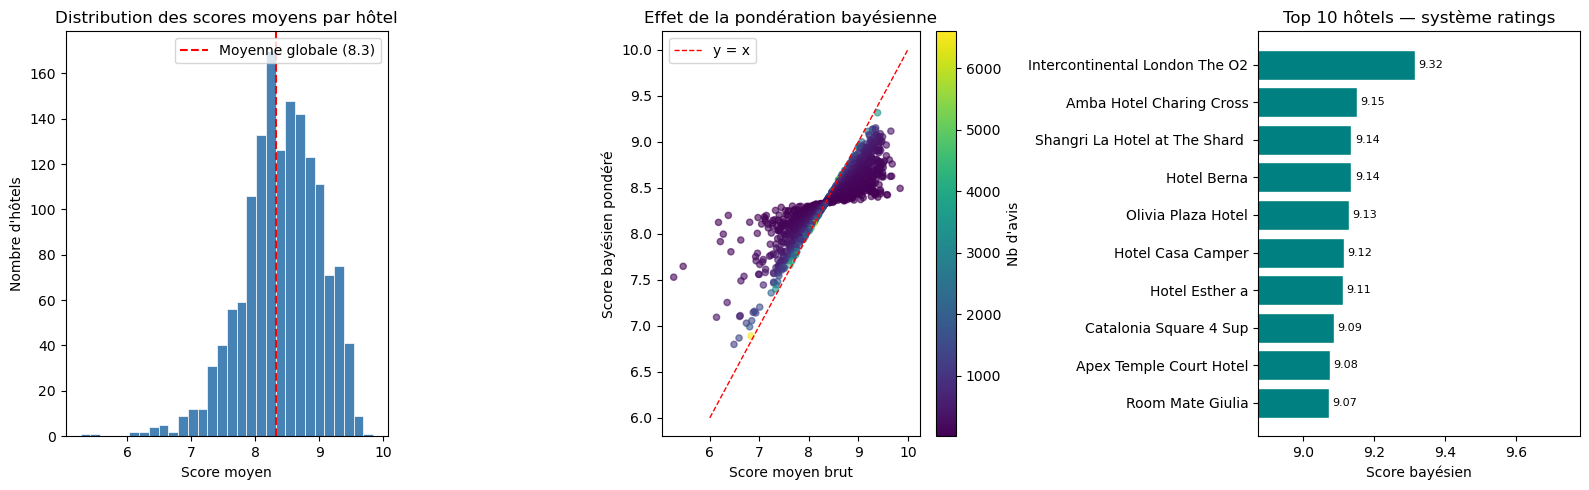

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# --- Graphique 1 : Distribution des scores moyens ---
ax1 = axes[0]
ax1.hist(hotel_stats['score_moyen'], bins=30, color='steelblue',
         edgecolor='white', linewidth=0.5)
ax1.axvline(m, color='red', linestyle='--', linewidth=1.5, label=f'Moyenne globale ({m:.1f})')
ax1.set_title("Distribution des scores moyens par hôtel")
ax1.set_xlabel("Score moyen")
ax1.set_ylabel("Nombre d'hôtels")
ax1.legend()

# --- Graphique 2 : Score moyen vs Score bayésien ---
ax2 = axes[1]
ax2.scatter(hotel_stats['score_moyen'], hotel_stats['score_bayes'],
            c=hotel_stats['nb_avis'], cmap='viridis',
            alpha=0.6, s=20)
ax2.plot([6, 10], [6, 10], 'r--', linewidth=1, label='y = x')
ax2.set_xlabel("Score moyen brut")
ax2.set_ylabel("Score bayésien pondéré")
ax2.set_title("Effet de la pondération bayésienne")
ax2.legend()
sm = plt.cm.ScalarMappable(cmap='viridis',
     norm=plt.Normalize(hotel_stats['nb_avis'].min(),
                        hotel_stats['nb_avis'].max()))
plt.colorbar(sm, ax=ax2, label="Nb d'avis")

# --- Graphique 3 : Top 10 hôtels ---
ax3 = axes[2]
top10 = hotel_stats.head(10).copy()
# Noms raccourcis pour la lisibilité
top10['nom_court'] = top10['Hotel_Name'].str[:30]
bars = ax3.barh(top10['nom_court'][::-1], top10['score_bayes'][::-1],
                color='teal', edgecolor='white')
ax3.set_xlabel("Score bayésien")
ax3.set_title("Top 10 hôtels — système ratings")
ax3.set_xlim(left=top10['score_bayes'].min() - 0.2)
for bar, score in zip(bars, top10['score_bayes'][::-1]):
    ax3.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2,
             f'{score:.2f}', va='center', fontsize=8)

plt.tight_layout()
plt.savefig('../results/visualizations/recommandation_ratings.png', dpi=150, bbox_inches='tight')
plt.show()

In [7]:
# Corrélation entre classement par score brut vs score bayésien
hotel_stats['rang_brut']   = hotel_stats['score_moyen'].rank(ascending=False)
hotel_stats['rang_bayes']  = hotel_stats['score_bayes'].rank(ascending=False)

corr, pval = stats.spearmanr(hotel_stats['rang_brut'], hotel_stats['rang_bayes'])
print(f"Corrélation de Spearman (brut vs bayésien) : {corr:.3f}  (p={pval:.4f})")

# Hôtels dont le rang change le plus entre les deux méthodes
hotel_stats['diff_rang'] = (hotel_stats['rang_brut'] - hotel_stats['rang_bayes']).abs()

print("\nHôtels les plus affectés par la pondération bayésienne :")
print(hotel_stats.nlargest(5, 'diff_rang')[
    ['Hotel_Name', 'nb_avis', 'score_moyen', 'score_bayes', 'diff_rang']
].to_string(index=False))

# Sauvegarde pour la comparaison avec le système sentiments (étape suivante)
hotel_stats.to_csv('../results/hotel_stats_ratings.csv', index=False)
print("\nFichier sauvegardé : results/hotel_stats_ratings.csv")

Corrélation de Spearman (brut vs bayésien) : 0.945  (p=0.0000)

Hôtels les plus affectés par la pondération bayésienne :
                        Hotel_Name  nb_avis  score_moyen  score_bayes  diff_rang
            Palais Coburg Residenz       17     9.394118     8.397736      655.0
               Hotel Eiffel Blomet       20     9.590000     8.422316      640.0
                     Drawing Hotel       21     9.576190     8.425428      634.0
45 Park Lane Dorchester Collection       26     9.446154     8.433696      594.0
                Hotel Dupond Smith       25     9.344000     8.421226      580.0

Fichier sauvegardé : results/hotel_stats_ratings.csv
